In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "tests":
    ROOT = ROOT.parent
APP_DIR = ROOT / "app"
if str(APP_DIR) not in sys.path:
    sys.path.insert(0, str(APP_DIR))
sms_path = ROOT / "docs" / "sms_conversations.json"
if not sms_path.exists():
    raise FileNotFoundError(sms_path)


In [2]:
%matplotlib inline
import json
from tqdm import tqdm
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from modules.main_agent import MainAgent

def plot_confusion_matrix(real_answers, answers):
    labels = ["End", "Continue", "Schedule"]
    ConfusionMatrixDisplay.from_predictions(real_answers, answers, labels=labels)
    plt.show()

def examples(conversations):
    rows = []
    for conversation in conversations:
        turns = conversation["turns"]
        messages = []
        timestamps = []
        for i, turn in enumerate(turns):
            new_label = None
            if turn["speaker"] == "candidate":
                new_label = turns[i+1]["label"]
            messages.append(turn['speaker'] + ': ' + turn['text'])
            timestamps.append(turn["timestamp_utc"])
            rows.append({
                "conversation_id": conversation["conversation_id"],
                "turn_id": turn["turn_id"],
                "messages_list": list(messages),
                "expect_end": new_label == "end",
                "expect_schedule": new_label == "schedule",
                "label": new_label,
                "timestamps": list(timestamps),
            })
    return rows

def predicted(action):
    if action == "End Conversation":
        return "End"
    if action == "Schedule Interview":
        return "Schedule"
    return "Continue"

def test_main_agent(conversations):
    main_agent = MainAgent()
    main_agent.job.set_title("Python Developer")
    main_agent.scheduling_advisor.set_position("Python Developer")
    answers = []
    real_answers = []
    for i, conversation in tqdm(enumerate(conversations), desc="Testing main agent"):
        messages = conversation["messages_list"]
        if messages[-1].startswith("recruiter:"):
            continue
        if conversation["label"] is None:
            continue
        main_agent.reset_messages()
        main_agent.add_multiple_messages(messages, "user", conversation["timestamps"])
        main_agent.reset_advisors()
        decision, action = main_agent.message_workflow()
        answers.append(predicted(action))
        real_answers.append(conversation["label"].capitalize())
    correct_answers = [a == b for a, b in zip(answers, real_answers)]
    plot_confusion_matrix(real_answers, answers)
    print(f"main agent accuracy: {100 * sum(correct_answers) / len(correct_answers):.1f}%")
    return correct_answers

/Users/gilsagie/GenAI_Course/final_project_submit/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1117 16:00:28.233000 23942 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


2026-11-17 16:00:35.437 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 6038.39it/s]
Testing main agent: 103it [02:14,  1.31s/it]


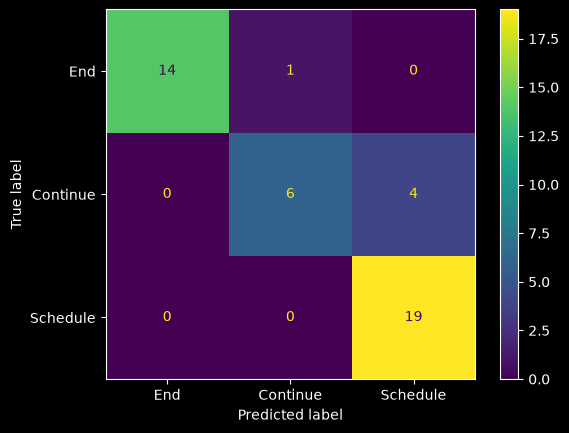

main agent accuracy: 88.6%


[True,
 True,
 True,
 False,
 True,
 True,
 True,
 False,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True]

In [3]:
sms_conversation = json.load(open(sms_path))
rows = examples(sms_conversation)
test_main_agent(rows)
